In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
DATA_PATH = "../data/raw/heart.csv"

df = pd.read_csv(DATA_PATH)
print("Original shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

Original shape: (939, 12)
Duplicate rows: 21


In [107]:
clean_df = df.drop_duplicates().copy()
import os

os.makedirs("../data/processed", exist_ok=True)

clean_df.to_csv(
    "../data/processed/real_cleaned_heart.csv",
    index=False
)

print("Shape after removing duplicates:", clean_df.shape)
print("\\nTarget distribution:")
print(clean_df["HeartDisease"].value_counts().sort_index())

Shape after removing duplicates: (918, 12)
\nTarget distribution:
HeartDisease
0    410
1    508
Name: count, dtype: int64


In [108]:
categorical_columns = [
    "Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"
]
numerical_columns = [
    "Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"
]

X = clean_df.drop(columns="HeartDisease").copy()
y = clean_df["HeartDisease"].copy()

X[["RestingBP", "Cholesterol"]] = X[
    ["RestingBP", "Cholesterol"]
].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training rows: 734
Testing rows: 184
\nTraining target distribution:
HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64
\nTesting target distribution:
HeartDisease
1    0.554
0    0.446
Name: proportion, dtype: float64


In [109]:
def build_preprocessor(scale_numeric=False):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numerical_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ])


models = {
    "Logistic Regression": Pipeline([
        ("preprocessing", build_preprocessor(scale_numeric=True)),
        ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessing", build_preprocessor()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocessing", build_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

In [110]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for model_name, pipeline in models.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring=["accuracy", "f1", "roc_auc"],
        n_jobs=-1
    )
    cv_rows.append({
        "Model": model_name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC", ascending=False)
display(cv_results.round(3))

,Model,CV Accuracy,CV F1,CV ROC-AUC
2,Random Forest,0.856,0.873,0.928
0,Logistic Regression,0.847,0.863,0.922
1,Decision Tree,0.796,0.814,0.794


In [111]:
fitted_models = {}
test_rows = []
predictions = {}

for model_name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    fitted_models[model_name] = pipeline

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    predictions[model_name] = (y_pred, y_prob)

    test_rows.append({
        "Model": model_name,
        "Train Accuracy": accuracy_score(y_train, pipeline.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_results = pd.DataFrame(test_rows).sort_values("ROC-AUC", ascending=False)
display(test_results.round(3))

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.858,0.886,0.886,0.912,0.899,0.933
2,Random Forest,1.000,0.886,0.886,0.912,0.899,0.931
1,Decision Tree,1.000,0.777,0.802,0.794,0.798,0.775


\n===== Logistic Regression =====
              precision    recall  f1-score   support

  No Disease       0.89      0.85      0.87        82
     Disease       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184



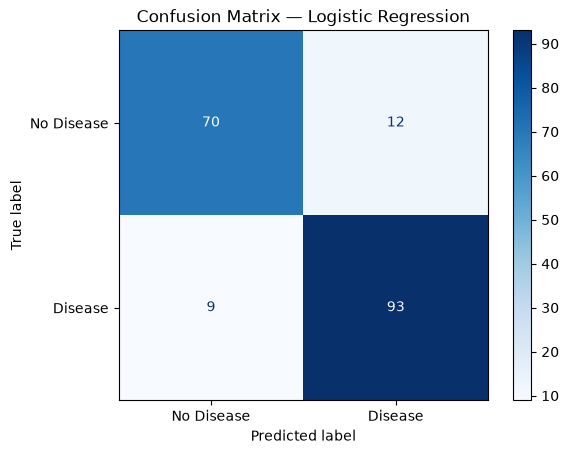

\n===== Decision Tree =====
              precision    recall  f1-score   support

  No Disease       0.75      0.76      0.75        82
     Disease       0.80      0.79      0.80       102

    accuracy                           0.78       184
   macro avg       0.77      0.78      0.77       184
weighted avg       0.78      0.78      0.78       184



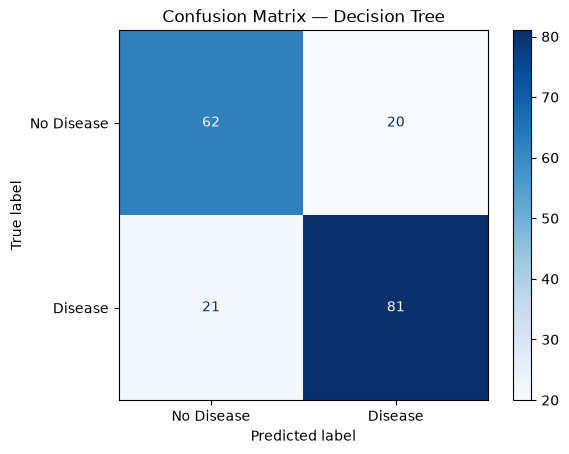

\n===== Random Forest =====
              precision    recall  f1-score   support

  No Disease       0.89      0.85      0.87        82
     Disease       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184



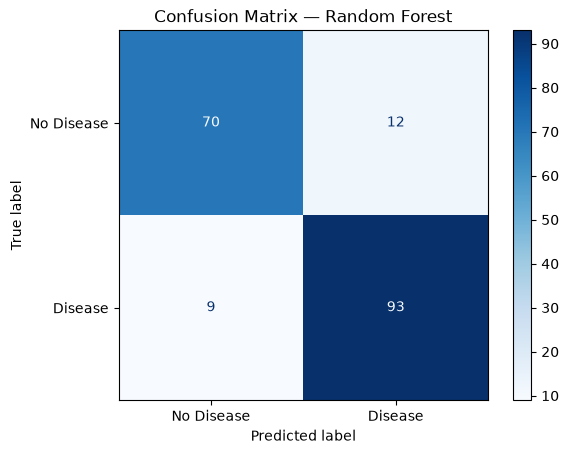

In [112]:
for model_name, (y_pred, y_prob) in predictions.items():
    print(f"\\n===== {model_name} =====")
    print(classification_report(
        y_test, y_pred, target_names=["No Disease", "Disease"], zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["No Disease", "Disease"], cmap="Blues"
    )
    plt.title(f"Confusion Matrix — {model_name}")
    plt.show()

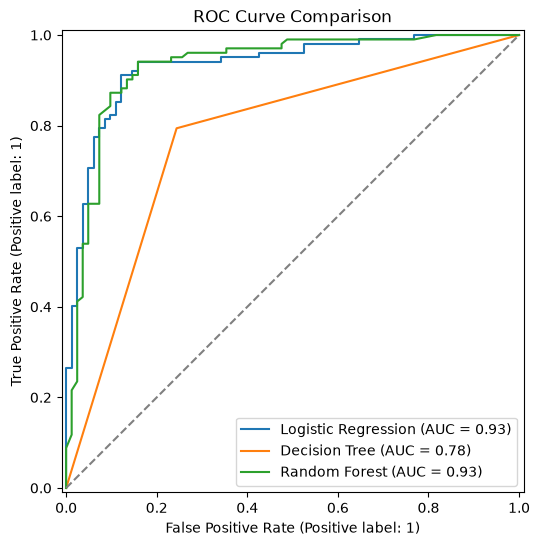

In [113]:
plt.figure(figsize=(8, 6))
for model_name, (y_pred, y_prob) in predictions.items():
    RocCurveDisplay.from_predictions(
        y_test, y_prob, name=model_name, ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.title("ROC Curve Comparison")
plt.show()

In [114]:
import joblib

os.makedirs("../models", exist_ok=True)
for model_name, pipeline in fitted_models.items():
    filename = model_name.lower().replace(" ", "_") + "_pipeline.joblib"
    joblib.dump(pipeline, f"../models/{filename}")
    print("Saved:", filename)

Saved: logistic_regression_pipeline.joblib
Saved: decision_tree_pipeline.joblib
Saved: random_forest_pipeline.joblib
